# pruebas extra con T12

antes he probado con dos y luego cuatro clases. aquí pruebo todos los fonemas, las 50 palabras y qué pasa al cambiar el día.

son pruebas para ver por dónde seguir, todavía no es un decodificador de frases.

cargar la configuración y preparar los registros de W&B. todos los ajustes están en el yaml.

In [ ]:
import os
import re
import sys
from collections import Counter
from copy import deepcopy
from pathlib import Path
from time import perf_counter
from typing import Any

import matplotlib.pyplot as plt
import numpy as np
import yaml
from scipy.io import loadmat
from scipy.linalg import solve

raiz = next(
    p for p in (Path.cwd(), *Path.cwd().parents)
    if (p / "configs").is_dir() and (p / "src").is_dir()
)
os.chdir(raiz)
if str(raiz) not in sys.path:
    sys.path.insert(0, str(raiz))

from src.data.speech import load_session
from src.utils.seed import fijar_seed
from src.utils.tracking import abrir_run, registrar

cfg = yaml.safe_load(
    Path("configs/exploracion_fomen_completo.yaml").read_text(encoding="utf-8")
)
salida = Path(cfg["salida"])
salida.mkdir(parents=True, exist_ok=True)
os.environ["WANDB_DIR"] = str(salida)
os.environ["WANDB_CACHE_DIR"] = str(salida / "cache")
os.environ["WANDB_CONFIG_DIR"] = str(salida / "config")
os.environ["WANDB_SILENT"] = "true"
os.environ["WANDB_CONSOLE"] = "off"
fijar_seed(cfg["experimento"]["seed"])

print("Configuración cargada. W&B:", cfg["wandb"]["modo"])

Configuración cargada. W&B: offline


cargar los ensayos ,guardo la media de cada señal, y también la media en tres partes del ensayo para probarla después.

In [2]:
def leer_tarea(archivo: str) -> dict[str, Any]:
    """Lee etiquetas, bloques y características sin normalizar los datos."""
    datos = loadmat(
        archivo,
        variable_names=[
            "cueList", "trialCues", "goTrialEpochs", "delayTrialEpochs",
            "blockNum", "trialState", "xpcClock", "tx1", "spikePow",
        ],
    )
    cues = np.array([str(c.ravel()[0]) for c in datos["cueList"].ravel()])
    ids = datos["trialCues"].ravel().astype(int) - 1
    etiquetas = cues[ids]
    indices = np.flatnonzero(~np.isin(etiquetas, cfg["controles"]))
    go = datos["goTrialEpochs"].astype(int)
    espera = datos["delayTrialEpochs"].astype(int)
    bloques_por_bin = datos["blockNum"].ravel().astype(int)
    estado = datos["trialState"].ravel()
    reloj = datos["xpcClock"].ravel().astype(np.int64)
    rasgos = {nombre: [] for nombre in cfg["rasgos"]}
    bloques = []

    for indice in indices:
        inicio, fin = go[indice]
        if not 1 <= inicio <= fin <= len(estado):
            raise ValueError("Un ensayo tiene índices fuera de la grabación.")
        # MATLAB empieza en 1 y su final está incluido.
        fragmento_go = slice(inicio - 1, fin)
        bloque = bloques_por_bin[inicio - 1]
        if np.any(bloques_por_bin[fragmento_go] != bloque):
            raise ValueError("Un ensayo cruza dos bloques.")
        if np.any(estado[fragmento_go] != 1):
            raise ValueError("El fragmento no coincide con el periodo go.")
        paso_ms = round(cfg["bin_segundos"] * 1000)
        if np.any(np.diff(reloj[fragmento_go]) != paso_ms):
            raise ValueError("Hay un salto de tiempo dentro de un ensayo.")
        bloques.append(bloque)

        for nombre, ajuste in cfg["rasgos"].items():
            epocas = espera if ajuste["periodo"] == "delay" else go
            ini, final = epocas[indice]
            canal_ini, canal_fin = cfg["areas"][ajuste["area"]]
            partes = []
            for senal in ajuste["senales"]:
                fragmento = datos[senal][ini - 1:final, canal_ini:canal_fin]
                ventanas = np.array_split(fragmento, ajuste["ventanas"], axis=0)
                partes.append(np.concatenate([
                    ventana.mean(axis=0, dtype=np.float64)
                    for ventana in ventanas
                ]))
            rasgos[nombre].append(np.concatenate(partes))

    matrices = {nombre: np.stack(filas) for nombre, filas in rasgos.items()}
    if any(not np.isfinite(x).all() for x in matrices.values()):
        raise ValueError("Hay características con valores inválidos.")
    return {
        "y": etiquetas[indices],
        "bloques": np.asarray(bloques),
        "X": matrices,
    }


tareas = {}
for nombre, ajuste in cfg["tareas"].items():
    tarea = leer_tarea(ajuste["archivo"])
    tareas[nombre] = tarea
    conteos = Counter(tarea["y"])
    print(
        f'{ajuste["nombre"]}: {len(tarea["y"])} ensayos | '
        f'{len(conteos)} clases | {len(np.unique(tarea["bloques"]))} bloques'
    )

Fonemas del 21: 624 ensayos | 39 clases | 8 bloques
Fonemas del 26: 780 ensayos | 39 clases | 10 bloques
50 palabras: 1000 ensayos | 50 clases | 10 bloques
Movimientos de la cara: 660 ensayos | 33 clases | 10 bloques


quedan 624 y 780 ensayos de fonemas, 1.000 de palabras y 660 de movimientos.
cada tarea tiene sus propios bloques

hago dos clasificadores: los centroides que ya usamos y LDA, que aprende una separación lineal entre clases.

In [3]:
def ajustar_modelo(
    X: np.ndarray, y: np.ndarray, nombre: str
) -> dict[str, Any]:
    """Ajusta la normalización y el clasificador usando solo entrenamiento."""
    inicio = perf_counter()
    clases = np.unique(y)
    media = X.mean(axis=0)
    escala = X.std(axis=0)
    escala[escala == 0] = cfg["normalizacion"]["escala_si_cero"]
    X_norm = (X - media) / escala
    centroides = np.stack([
        X_norm[y == clase].mean(axis=0) for clase in clases
    ])
    ajuste = cfg["modelos"][nombre]
    pesos = None

    if ajuste["tipo"] == "lda":
        residuos = np.concatenate([
            X_norm[y == clase] - centroides[i]
            for i, clase in enumerate(clases)
        ])
        covarianza = residuos.T @ residuos / (len(y) - len(clases))
        regularizacion = ajuste["regularizacion"]
        covarianza *= 1 - regularizacion
        covarianza.flat[::covarianza.shape[0] + 1] += regularizacion
        pesos = solve(covarianza, centroides.T, assume_a="pos")
    elif ajuste["tipo"] != "centroides":
        raise ValueError("Modelo desconocido.")

    return {
        "clases": clases, "media": media, "escala": escala,
        "centroides": centroides, "pesos": pesos,
        "tipo": ajuste["tipo"], "ajuste_s": perf_counter() - inicio,
    }


def predecir(modelo: dict[str, Any], X: np.ndarray) -> np.ndarray:
    """Predice con la normalización aprendida durante el entrenamiento."""
    X_norm = (X - modelo["media"]) / modelo["escala"]
    centros = modelo["centroides"]
    if modelo["tipo"] == "centroides":
        puntuaciones = 2 * X_norm @ centros.T - np.sum(centros ** 2, axis=1)
    else:
        pesos = modelo["pesos"]
        puntuaciones = X_norm @ pesos - 0.5 * np.sum(centros * pesos.T, axis=1)
    return modelo["clases"][puntuaciones.argmax(axis=1)]

repetir la prueba dejando fuera un bloque cada vez, como en el otro notebook,
así cada ensayo se evalúa con un modelo que no ha visto su bloque.

In [4]:
def iniciar_registro(nombre: str) -> Any:
    """Abre el registro obligatorio de W&B para una prueba."""
    config_run = deepcopy(cfg)
    config_run["experimento"]["nombre"] += "_" + nombre
    run = abrir_run(config_run)
    if run is None:
        raise RuntimeError("Hace falta W&B para registrar el entrenamiento.")
    return run


def validar_bloques(
    tarea: dict[str, Any], rasgos: str, modelo: str, run: Any, nombre: str
) -> dict[str, Any]:
    """Evalúa cada bloque una vez y registra todos los ajustes en W&B."""
    if run is None:
        raise RuntimeError("El entrenamiento debe tener un registro de W&B.")
    X, y, bloques = tarea["X"][rasgos], tarea["y"], tarea["bloques"]
    predicciones = np.empty_like(y)
    tiempo = 0.0
    por_bloque = []

    for bloque in np.unique(bloques):
        validacion = bloques == bloque
        entrenamiento = ~validacion
        if set(y[validacion]) - set(y[entrenamiento]):
            raise ValueError("Una clase no está en el entrenamiento.")
        aprendido = ajustar_modelo(X[entrenamiento], y[entrenamiento], modelo)
        predicciones[validacion] = predecir(aprendido, X[validacion])
        aciertos = int(np.sum(predicciones[validacion] == y[validacion]))
        tiempo += aprendido["ajuste_s"]
        por_bloque.append({
            "bloque": int(bloque), "aciertos": aciertos,
            "total": int(sum(validacion)),
        })
        registrar(run, {
            "prueba": nombre, "bloque": int(bloque),
            "accuracy_bloque": aciertos / sum(validacion),
            "ensayos_train": int(sum(entrenamiento)),
            "ensayos_validacion": int(sum(validacion)),
            "ajuste_s": aprendido["ajuste_s"],
        })

    return {
        "aciertos": int(np.sum(predicciones == y)), "total": len(y),
        "accuracy": float(np.mean(predicciones == y)),
        "ajuste_s": tiempo, "por_bloque": por_bloque,
    }


resultados_cv = {}


def comparar(grupo: str) -> list[dict[str, Any]]:
    """Ejecuta una comparación y reutiliza resultados ya calculados."""
    resultados = []
    with iniciar_registro(grupo) as run:
        for tarea, rasgos, modelo in cfg["comparaciones"][grupo]:
            clave = (tarea, rasgos, modelo)
            if clave not in resultados_cv:
                resultados_cv[clave] = validar_bloques(
                    tareas[tarea], rasgos, modelo, run, "/".join(clave)
                )
            resultado = resultados_cv[clave]
            resultados.append(resultado)
            print(
                f'{cfg["tareas"][tarea]["nombre"]} | {rasgos} | {modelo}: '
                f'{resultado["aciertos"]}/{resultado["total"]} '
                f'→ {resultado["accuracy"]:.1%}'
            )
    return resultados

probar los 39 fonemas, no solo los cuatro que he elegido antes.

Quiero ver si sigue habiendo diferencias al tener muchas más clases.

In [5]:
resultados_fonemas = comparar("fonemas")

Fonemas del 21 | tx_media | centroides: 324/624 → 51.9%
Fonemas del 26 | tx_media | centroides: 431/780 → 55.3%
Fonemas del 21 | ambas_media | lda: 436/624 → 69.9%
Fonemas del 26 | ambas_media | lda: 549/780 → 70.4%


Con los centroides y tx1 acierta 324/624 (51,9 %) el día 21 y 431/780 (55,3 %) el 26

Con las dos señales y LDA llega a 69,9 % y 70,4 %



Comparar tx1, la potencia y las dos juntas con cada modelo

ahora quiero separar qué mejora viene de la señal y qué mejora viene del clasificador.

In [6]:
resultados_senales = comparar("senales")

Fonemas del 26 | tx_media | centroides: 431/780 → 55.3%
Fonemas del 26 | potencia_media | centroides: 412/780 → 52.8%
Fonemas del 26 | ambas_media | centroides: 446/780 → 57.2%
Fonemas del 26 | tx_media | lda: 512/780 → 65.6%
Fonemas del 26 | potencia_media | lda: 519/780 → 66.5%
Fonemas del 26 | ambas_media | lda: 549/780 → 70.4%


con centroides, tx1 da 55,3 %, la potencia 52,8 % y las dos juntas 57,2 %,
con LDA salen 65,6 %, 66,5 % y 70,4 %. en esta prueba ayuda juntar las señales y también cambiar el modelo.

probar los canales de 6v, los del área 44 y todos juntos,
quiero comprobar si usar más canales ayuda o solo añade cosas que no nos sirven tanto.

In [7]:
resultados_areas = comparar("areas")

Fonemas del 26 | ambas_media | lda: 549/780 → 70.4%
Fonemas del 26 | ambas_44 | lda: 110/780 → 14.1%
Fonemas del 26 | ambas_todos | lda: 531/780 → 68.1%


6v da 70,4 %, el área 44 da 14,1 % y todos juntos 68,1 %,
para esta prueba me quedaría con los primeros 128 canales de 6v.

pasar a las 50 palabras del otro archivo

cada palabra tiene 20 ensayos.
quiero ver si podemos distinguir palabras de la misma manera

In [8]:
resultados_palabras = comparar("palabras")

50 palabras | tx_media | centroides: 781/1000 → 78.1%
50 palabras | tx_media | lda: 925/1000 → 92.5%
50 palabras | ambas_media | lda: 959/1000 → 95.9%


con tx1 y centroides acierta 781/1.000 (78,1 %).
con las dos señales y LDA acierta 959/1.000 (95,9 %).
funciona bastante bien, pero solo está eligiendo entre estas 50 palabras del mismo día

dividir cada ensayo en tres partes y guardar una media por parte

quiero ver si ayuda conservar algo del orden temporal, en vez de hacer una sola media de todo.

Fonemas del 26 | ambas_media | lda: 549/780 → 70.4%
Fonemas del 26 | ambas_3_ventanas | lda: 552/780 → 70.8%
50 palabras | ambas_media | lda: 959/1000 → 95.9%
50 palabras | ambas_3_ventanas | lda: 981/1000 → 98.1%


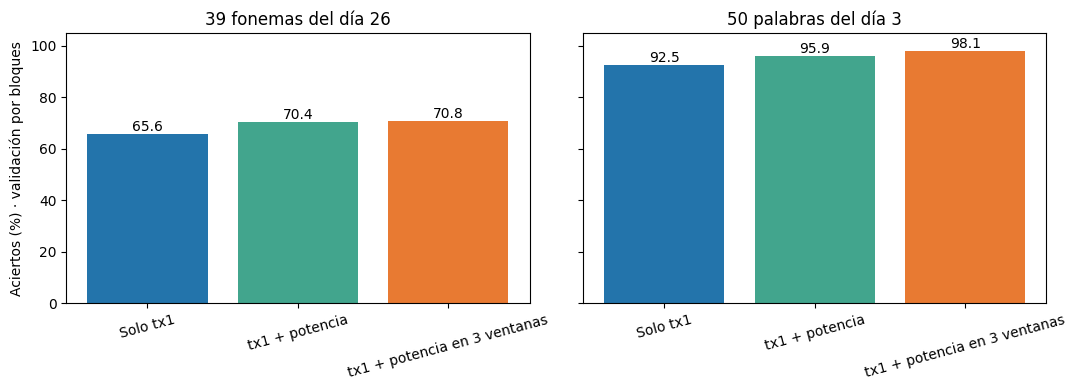

In [9]:
resultados_ventanas = comparar("ventanas")

grafico = cfg["grafico"]
fig, ejes = plt.subplots(
    1, len(grafico["tareas"]), figsize=grafico["tamano"], sharey=True
)
for eje, tarea, titulo in zip(ejes, grafico["tareas"], grafico["titulos"]):
    valores = [
        100 * resultados_cv[(tarea, rasgos, grafico["modelo"])]["accuracy"]
        for rasgos in grafico["rasgos"]
    ]
    barras = eje.bar(grafico["etiquetas"], valores, color=grafico["colores"])
    eje.bar_label(barras, fmt="%.1f")
    eje.set_title(titulo)
    eje.set_ylim(0, 105)
    eje.tick_params(axis="x", rotation=15)
ejes[0].set_ylabel("Aciertos (%) · validación por bloques")
fig.tight_layout()
fig.savefig(salida / grafico["archivo"], dpi=grafico["dpi"])
plt.show()

en fonemas apenas cambia: de 70,4 % a 70,8 %

en palabras pasa de 95,9 % a 98,1 %, 981/1.000 aciertos.
aquí sí parece útil conservar algo de cómo cambia la señal durante el ensayo.

entrenar con un día y evaluar en el otro, usando ahora todos los fonemas.
quiero comprobar si el problema del otro notebook al pasar de Bah y Pah entre días sigue pasando.

In [10]:
resultados_otro_dia = []
ajuste = cfg["otro_dia"]
with iniciar_registro("otro_dia") as run:
    for origen, destino in ajuste["direcciones"]:
        fuente, objetivo = tareas[origen], tareas[destino]
        rasgos = ajuste["rasgos"]
        aprendido = ajustar_modelo(
            fuente["X"][rasgos], fuente["y"], ajuste["modelo"]
        )
        predicciones = predecir(aprendido, objetivo["X"][rasgos])
        aciertos = int(np.sum(predicciones == objetivo["y"]))
        total = len(objetivo["y"])
        resultado = {
            "origen": origen, "destino": destino,
            "aciertos": aciertos, "total": total,
            "accuracy": aciertos / total, "ajuste_s": aprendido["ajuste_s"],
        }
        resultados_otro_dia.append(resultado)
        registrar(run, resultado)
        print(f"{origen} → {destino}: {aciertos}/{total} → {aciertos / total:.1%}")

fonemas_21 → fonemas_26: 80/780 → 10.3%
fonemas_26 → fonemas_21: 16/624 → 2.6%


del 21 al 26 acierta 80/780 (10,3 %)

al revés, 16/624 (2,6 %)

dentro de cada día rondaba el 70 %, así que sigue costando mucho pasar de un día a otro.

mezclar las etiquetas de entrenamiento dentro de cada bloque y repetir la prueba.
las etiquetas de validación se quedan bien

para ver como se comporta que pasa cuando el modelo aprende asociaciones equivocadas

In [11]:
resultados_mezclados = {}
ajuste = cfg["etiquetas_mezcladas"]
fijar_seed(cfg["experimento"]["seed"])
with iniciar_registro("etiquetas_mezcladas") as run:
    for nombre in ajuste["tareas"]:
        tarea = tareas[nombre]
        X = tarea["X"][ajuste["rasgos"]]
        y, bloques = tarea["y"], tarea["bloques"]
        accuracies = []

        for repeticion in range(ajuste["repeticiones"]):
            mezcladas = y.copy()
            for bloque in np.unique(bloques):
                indices = np.flatnonzero(bloques == bloque)
                mezcladas[indices] = np.random.permutation(mezcladas[indices])
            predicciones = np.empty_like(y)

            for bloque in np.unique(bloques):
                validacion = bloques == bloque
                aprendido = ajustar_modelo(
                    X[~validacion], mezcladas[~validacion], ajuste["modelo"]
                )
                predicciones[validacion] = predecir(aprendido, X[validacion])
                registrar(run, {
                    "tarea": nombre, "repeticion": repeticion,
                    "bloque": int(bloque), "ajuste_s": aprendido["ajuste_s"],
                })

            accuracy = float(np.mean(predicciones == y))
            accuracies.append(accuracy)
            registrar(run, {
                "tarea": nombre, "repeticion": repeticion,
                "accuracy_mezcladas": accuracy,
            })

        resultados_mezclados[nombre] = accuracies
        print(
            f'{cfg["tareas"][nombre]["nombre"]}: '
            f'media {np.mean(accuracies):.2%} | '
            f'azar {1 / len(np.unique(y)):.2%}'
        )

Fonemas del 26: media 2.49% | azar 2.56%
50 palabras: media 1.85% | azar 2.00%


al mezclar las etiquetas sale aproximadamente si que parece lo que se espera por azar: 2,49 % en fonemas y 1,85 % en palabras

probar también el periodo de espera, antes del go

quiero saber si parte de la información ya estaba cuando la participante había visto qué tenía que intentar

In [12]:
resultados_espera = comparar("espera")

Fonemas del 26 | ambas_media | lda: 549/780 → 70.4%
Fonemas del 26 | ambas_espera | lda: 613/780 → 78.6%


con la espera acierta 613/780 (78,6 %), incluso más que usando el go (70,4 %)


puede haber información de la indicación o de la preparación

estos aciertos no nos dicen cuándo se produjo cada fonema

voy a probar con los movimientos de la cara

quiero ver si el mismo método también distingue estas acciones

In [13]:
resultados_movimientos = comparar("movimientos")

Movimientos de la cara | ambas_media | lda: 631/660 → 95.6%


acierta 631/660 (95,6 %) entre 33 movimientos.
también distingue bastante bien estas condiciones dentro de ese día.

mirar todas las sesiones de frases de entrenamiento con el mismo lector


quiero ver los datos y ver cuánto duran los ensayos antes de empezar a preparar las secuencias

In [14]:
archivos = sorted(Path(cfg["frases"]["carpeta"]).glob("*.mat"))
if not archivos:
    raise FileNotFoundError("No se encontraron las frases de entrenamiento.")

longitudes = []
textos = Counter()
vocabulario = set()
textos_vacios = 0
ejemplo = None
patron = re.compile(cfg["frases"]["patron_palabras"])

for archivo in archivos:
    sesion = load_session(archivo)
    for ensayo in sesion.trials:
        longitudes.append(len(ensayo.threshold_crossings))
        palabras = patron.findall((ensayo.text or "").lower())
        textos_vacios += int(not palabras)
        textos[" ".join(palabras)] += 1
        vocabulario.update(palabras)
        if ejemplo is None:
            ejemplo = (ensayo.text, ensayo.features_6v().shape)

duraciones = np.asarray(longitudes) * cfg["bin_segundos"]
print("Sesiones:", len(archivos))
print("Ensayos:", len(longitudes))
print(f"Horas de grabación: {duraciones.sum() / 3600:.2f}")
print(
    f"Duración: mínimo {duraciones.min():.2f} s | "
    f"mediana {np.median(duraciones):.2f} s | máximo {duraciones.max():.2f} s"
)
print("Textos vacíos:", textos_vacios)
print("Palabras diferentes:", len(vocabulario))
print("Repeticiones extra de texto:", sum(n - 1 for n in textos.values()))
print("Ejemplo:", ejemplo[0])
print("Forma con las dos señales de 6v:", ejemplo[1])
print("Todos los ensayos han pasado las comprobaciones de valores del lector.")

Sesiones: 24
Ensayos: 8800
Horas de grabación: 15.38
Duración: mínimo 1.94 s | mediana 5.94 s | máximo 18.12 s
Textos vacíos: 0
Palabras diferentes: 6543
Repeticiones extra de texto: 91
Ejemplo: Nuclear rockets can destroy airfields with ease.
Forma con las dos señales de 6v: (478, 256)
Todos los ensayos han pasado las comprobaciones de valores del lector.


hay 8.800 ensayos en 24 sesiones, unas 15,4 horas de grabación


las duraciones van de 1,94 a 18,12 segundos y no hay textos vacíos

las señales han pasado las comprobaciones del lector

también hay 91 repeticiones extra de texto

aquí ya no basta con elegir una clase hay que que sacar una secuencia de fonemas o texto de cada grabación